# CivicFix: classification and description experiments
EGN 6216 · Fall 2026

One submission notebook: OpenCLIP classification on 43 development photos, followed by Qwen3-VL descriptions and OpenCLIP text–image scoring on a frozen 20-photo subset. Each experiment includes a baseline, error review and one prompt change.

## Setup
The experiment ran on an Apple M5 Mac with 24 GiB memory and Python 3.12.15: CPU, float32, batch size 1 and four PyTorch threads. It uses pretrained weights, with no training or paid service. Package versions are printed below.

Sources: [OpenCLIP](https://github.com/mlfoundations/open_clip), [OpenAI CLIP license](https://github.com/openai/CLIP/blob/main/LICENSE), and [model card](https://github.com/openai/CLIP/blob/main/model-card.md). The release uses MIT terms with research-use guidance. Photo licenses and attribution are in the dataset manifest.

In [1]:
import os, sys, json, platform, tempfile, socket
from pathlib import Path
from importlib.metadata import version
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from experiments.first_model_exploration.benchmark import (
    ROOT, HERE, CATEGORIES, Runtime, inspect_data, load_prompts, run,
    evaluate, assert_one_change, write_new, digest, sha256)
from scripts.dataset_tools import near_duplicate_pairs, image_path
assert Path.cwd() == ROOT, 'Execute from repository root'
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
pd.set_option('display.max_colwidth', 100)
print('Python', platform.python_version(), '|', platform.system(), platform.machine())
display(pd.DataFrame([{'package':p,'version':version(p)} for p in
 ['torch','torchvision','open_clip_torch','Pillow','numpy','pandas','matplotlib','nbclient']]))
(ROOT / '.runtime/clip-runs').mkdir(parents=True, exist_ok=True)
RUN_ROOT = Path(tempfile.mkdtemp(prefix='exploration-', dir=ROOT / '.runtime/clip-runs'))
print('Private raw artifacts:', RUN_ROOT.relative_to(ROOT))
# Keep model loading and inference offline.
# Jupyter still needs loopback connections.
network_attempts = []
def network_guard(event, args):
    if event == 'socket.connect':
        address = args[1]
        if isinstance(address, tuple) and address[0] not in ('127.0.0.1','::1','localhost'):
            network_attempts.append('blocked external connection')
            raise RuntimeError('External networking disabled during local experiment')
sys.addaudithook(network_guard)

Python 3.12.15 | Darwin arm64


,package,version
0,torch,2.14.1
1,torchvision,0.29.1
2,open_clip_torch,3.3.0
3,Pillow,12.3.0
4,numpy,2.5.3
5,pandas,3.0.6
6,matplotlib,3.11.2
7,nbclient,0.11.0


Private raw artifacts: .runtime/clip-runs/exploration-nadqigy9


## Data preparation
Milestone 3 Section 6.5 designates all 43 photos as development examples. Both runs use this set; separate final test photos still need to be collected. `split.json` records the IDs and source-document hash.

The checks below cover dimensions, decoding, checksums, labels, balance, missing values and duplicates. Labels were curated by an agent, without independent human validation. No preprocessing is fitted to the data.

In [2]:
manifest, development, images, inspection = inspect_data()
split = inspection['split']
write_new(RUN_ROOT / 'inspection.json', inspection)
print('Dataset:', inspection['dataset_version'], '| commit:', inspection['dataset_commit'])
print('Manifest SHA-256:', inspection['manifest_sha256'])
print('Pool/development:', len(manifest), '/',len(development), '| held-out in pool:',len(split['held_out_ids']))
print('Section 6.5 source SHA-256:', split['source_sha256'])
print(inspection['changes'])
display(pd.Series(inspection['counts'], name='images').to_frame())
display(images[['width','height']].describe().round(1))
display(images.groupby(['format','mode']).size().rename('images').to_frame())
display(pd.Series(inspection['missing'],name='missing').to_frame())
print('Decoded:',len(images),'| hash mismatches: 0 | duplicate bytes:',inspection['duplicate_bytes'],
      '| inconsistent hash labels:',inspection['inconsistent_labels'],'| EXIF fields:',int(images.exif_fields.sum()))
display(manifest.license.value_counts().rename('photos').to_frame())
pairs = near_duplicate_pairs(development, ROOT / 'data')
display(pairs)
print('Average-hash candidates are screening results, not proof of event independence.')

Dataset: v1 | commit: 8394bf6d0d84c9dbf33e69258f0cd15ee4795ca4
Manifest SHA-256: 98f8e250316df8c1517b381445d05dbc8a98813020930438a506e72e75dd28f9
Pool/development: 43 / 43 | held-out in pool: 0
Section 6.5 source SHA-256: 5261add2087d167df733015522161c611c2f0fd3ddd2bf4062e12614a8accefc
Filled none; dropped none; original labels and unknown metadata unchanged.


,images
pothole,10
broken_streetlight,10
damaged_sign,10
leaking_hydrant,3
illegal_dumping,10


,width,height
count,43.0,43.0
mean,894.3,777.0
std,394.3,362.2
min,330.0,160.0
25%,551.0,480.0
50%,960.0,853.0
75%,1280.0,960.0
max,1280.0,1280.0


,,images
format,mode,
JPEG,RGB,43


,missing
image_id,0
filename,0
issue_type,0
source_name,0
source_url,0
download_url,0
source_version,0
author,0
license,0
license_url,0


Decoded: 43 | hash mismatches: 0 | duplicate bytes: 0 | inconsistent hash labels: 0 | EXIF fields: 0


,photos
license,
CC BY-SA 2.0,17
CC BY-SA 4.0,15
CC0,4
Public domain,3
CC BY 4.0,2
CC BY 2.0,1
CC BY-SA 3.0,1


,left_id,right_id,distance,same_label
0,commons-5000667ac9,commons-bb9ea4bd37,5,False
1,commons-bb9ea4bd37,commons-ddf392a527,6,False
2,commons-bb9ea4bd37,commons-f5eb1a435d,6,False


Average-hash candidates are screening results, not proof of event independence.


No images were dropped, labels changed or missing values filled. Six locations, 21 capture dates and all 43 weather values remain unknown. All images opened as RGB JPEGs and matched their checksums. No exact duplicates were found; three possible near-duplicate pairs were previously reviewed as different scenes.

There are 10 photos per category except hydrants, with only 3. Two hydrant labels rely on captions because the hydrant is not visible. The model receives pixels and fixed category prompts, without labels, filenames, captions or review notes.

## Model configuration
The AI component takes a photo and suggests one of CivicFix's five issue categories. It compares the image with category descriptions and returns the best match along with five similarity scores. This tests the category-suggestion stage that a user would review when preparing a report.

OpenCLIP `ViT-B-32` with `openai` weights was selected first because it works with the labeled photo collection, needs no additional training and runs on the available CPU. Other candidates include SigLIP, OpenCLIP ViT-B-16 and Qwen3-VL-4B-Instruct. The second part of this notebook evaluates Qwen descriptions offline; application integration remains future work.

Image validation, category-ID mapping and metric calculations are deterministic. Location confirmation, destination lookup, report rules and database operations are also non-AI parts of the planned app. The category-mapping check below tests valid IDs and rejects an unknown ID.

In [3]:
# Check category IDs and reject an unknown ID.
category_index = {category:i for i,category in enumerate(CATEGORIES)}
assert len(category_index)==5 and all(CATEGORIES[category_index[k]]==k for k in CATEGORIES)
try:
    category_index['unsupported']
except KeyError:
    print('Taxonomy round-trip and unknown-category rejection: PASS')
else:
    raise AssertionError('Unknown category accepted')
model_spec=json.loads((HERE / 'model.json').read_text())
assert sha256(ROOT / model_spec['local_path']) == model_spec['sha256']
print('Verified checkpoint:',model_spec['sha256'])
prompts_v1=load_prompts(HERE / 'prompts/categories.v1.json')
display(pd.DataFrame([{'category':k,'prompts':v} for k,v in prompts_v1['prompts'].items()]))
runtime=Runtime(ROOT/model_spec['local_path'], model_spec['sha256'])
print(json.dumps(runtime.metadata,indent=2))
print('Model loading seconds (separate setup measurement):',runtime.load_seconds)

Taxonomy round-trip and unknown-category rejection: PASS


Verified checkpoint: 40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af


,category,prompts
0,pothole,"[A photo of a pothole in an asphalt road., A photo of missing pavement forming a hole in a road ..."
1,broken_streetlight,"[A photo of a damaged streetlight fixture., A photo of a broken streetlight pole or lamp., A pho..."
2,damaged_sign,"[A photo of a bent or damaged traffic sign., A photo of a broken street sign or signpost., A pho..."
3,leaking_hydrant,"[A photo of a fire hydrant with escaping water., A photo of water spraying from a fire hydrant.,..."
4,illegal_dumping,"[A photo of discarded rubbish piled beside a road., A photo of a pile of dumped household waste...."


/Users/vigne/Documents/vsCode/civicFix/.venv-inference/clip/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/vigne/Documents/vsCode/civicFix/.venv-inference/clip/lib/python3.12/site-packages/open_clip/factory.py:164: UserWarning: 'torch.load' received a zip file that looks like a TorchScript archive dispatching to 'torch.jit.load' (call 'torch.jit.load' directly to silence this warning)
  checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=weights_only)
/Users/vigne/Documents/vsCode/civicFix/.venv-inference/clip/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


{
  "model": "ViT-B-32",
  "pretrained_tag": "openai",
  "checkpoint_sha256": "40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af",
  "device": "cpu",
  "precision": "float32",
  "batch_size": 1,
  "threads": 4,
  "activation": "QuickGELU (OpenAI checkpoint native)",
  "seed": 6216,
  "deterministic_algorithms": true,
  "training_budget": "none (pretrained inference)",
  "tokenizer": "SimpleTokenizer",
  "tokenizer_bpe_sha256": "924691ac288e54409236115652ad4aa250f48203de50a9e4722a6ecd48d6804a",
  "context_length": 77,
  "preprocess": "Compose(\n    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)\n    CenterCrop(size=(224, 224))\n    MaybeConvertMode()\n    MaybeToTensor()\n    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))\n)",
  "platform": "Darwin",
  "machine": "arm64",
  "python": "3.12.15",
  "packages": {
    "torch": "2.14.1",
    "torchvision": "0.29.1",
    "open_clip_torch": "3.3.0",
    "Pill

## Inference
Model settings, prompts, image IDs and the seed are saved before inference. Standard CLIP preprocessing resizes and center-crops each image to 224 pixels, then normalizes it.

Each category has three descriptions. Their normalized embeddings are averaged and compared with the image embedding. The highest cosine similarity selects the category; these scores are not confidence probabilities.

The first image checks the input/output shapes. Predictions are saved before joining labels for evaluation. Failed attempts count as incorrect.

In [4]:
baseline_cfg, baseline_rows, baseline_metrics=run(runtime,development,split,
    HERE/'prompts/categories.v1.json', RUN_ROOT/'baseline')
first=baseline_rows[0]
assert first['status']=='success', first
assert first['input_shape']==[1,3,224,224] and first['embedding_shape']==[1,512]
assert len(first['scores'])==5 and isinstance(first['predicted_category'],str)
print('First real forward pass:',json.dumps(first,indent=2))
print('Frozen configuration:',baseline_cfg['configuration_sha256'])
print('Attempted:',len(baseline_rows),'| successes:',baseline_metrics['successful_predictions'],
      '| failures:',baseline_metrics['failures'])
# Show predictions and scores by image ID.
baseline_table=pd.DataFrame([{**{k:r.get(k) for k in ['image_id','status','predicted_category','top1_margin','latency_seconds']},
                              **r.get('scores',{})} for r in baseline_rows])
display(baseline_table)

First real forward pass: {
  "image_id": "commons-04258228ae",
  "status": "success",
  "error_type": null,
  "predicted_category": "damaged_sign",
  "scores": {
    "pothole": 0.23099112510681152,
    "broken_streetlight": 0.20389825105667114,
    "damaged_sign": 0.3053283095359802,
    "leaking_hydrant": 0.14866125583648682,
    "illegal_dumping": 0.22680504620075226
  },
  "top1_margin": 0.0743371844291687,
  "mode": "closed_set",
  "score_kind": "cosine_similarity",
  "simulated": false,
  "input_shape": [
    1,
    3,
    224,
    224
  ],
  "embedding_shape": [
    1,
    512
  ],
  "latency_seconds": 0.04109099999186583,
  "first_image_in_run": true
}
Frozen configuration: de6c0f34d4c33b14489d7781ebc0cd519f14b9cb4389c0442c9fb269d495cbf9
Attempted: 43 | successes: 43 | failures: 0


,image_id,status,predicted_category,top1_margin,latency_seconds,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping
0,commons-04258228ae,success,damaged_sign,0.074337,0.041091,0.230991,0.203898,0.305328,0.148661,0.226805
1,commons-0a68e3b438,success,pothole,0.028746,0.040096,0.330434,0.301688,0.281791,0.265747,0.270203
2,commons-0f02ab33ca,success,illegal_dumping,0.034545,0.032262,0.207142,0.227462,0.246653,0.169867,0.281198
3,commons-1b000da556,success,leaking_hydrant,0.013369,0.031440,0.294854,0.266527,0.279302,0.308223,0.284342
4,commons-1be7ba9610,success,damaged_sign,0.043131,0.033929,0.260078,0.267627,0.310758,0.213668,0.259058
5,commons-1ce17d43d9,success,illegal_dumping,0.023738,0.031465,0.225072,0.242423,0.248749,0.209844,0.272487
6,commons-2409b4bbcb,success,broken_streetlight,0.064957,0.040226,0.168848,0.305442,0.240485,0.224369,0.199850
7,commons-289e64dab5,success,damaged_sign,0.063458,0.031402,0.224491,0.247198,0.318801,0.223411,0.255342
8,commons-359e62bbe5,success,illegal_dumping,0.008518,0.031025,0.262175,0.275373,0.282361,0.227579,0.290879
9,commons-3e69e554ed,success,pothole,0.076136,0.040615,0.363261,0.283015,0.287126,0.261293,0.246749


## Evaluation
**Accuracy** measures correct category suggestions. **Macro-F1** gives each category equal weight despite the smaller hydrant class. Per-category precision, recall, F1 and support are also shown. Execution failures count as incorrect and as missed predictions for their true class; undefined metrics are set to zero.

Latency includes opening, decoding, preprocessing, encoding and scoring one image. Model loading and text encoding are timed separately; the first image is not pre-warmed.

Section 2.1 targets 95/100 requests within 10 seconds at one and three concurrent requests. This sequential classifier run does not test concurrency or the full app.

Frozen baseline 40/43 = 93.02%; macro-F1 0.9101


,precision,recall,f1,support,correct
category,,,,,
pothole,0.833333,1.000000,0.909091,10,10
broken_streetlight,0.909091,1.000000,0.952381,10,10
damaged_sign,1.000000,1.000000,1.000000,10,10
leaking_hydrant,1.000000,0.666667,0.800000,3,2
illegal_dumping,1.000000,0.800000,0.888889,10,8


,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping,execution_failure
pothole,10,0,0,0,0,0
broken_streetlight,0,10,0,0,0,0
damaged_sign,0,0,10,0,0,0
leaking_hydrant,1,0,0,2,0,0
illegal_dumping,1,1,0,0,8,0


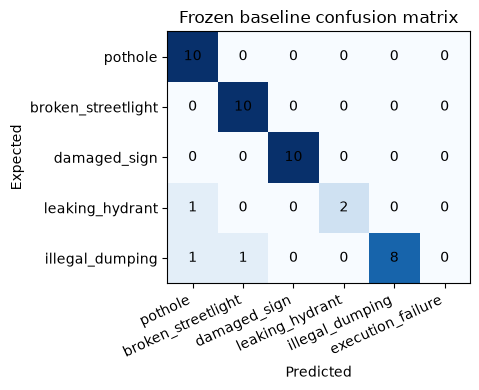

Latency seconds: {'mean': 0.03965478195256532, 'median': 0.0403874579933472, 'p95': 0.05080613689788151, 'maximum': 0.06567287500365637}
First image: 0.04109099999186583 | text prototype setup: 0.1924030420195777
Under 10 seconds: 43 / 43


In [5]:
def show_metrics(metrics,title):
    print(title, f"{metrics['correct']}/{metrics['attempted_n']} = {metrics['accuracy']:.2%}; macro-F1 {metrics['macro_f1']:.4f}")
    display(pd.DataFrame(metrics['per_class']).set_index('category'))
    matrix=pd.DataFrame(metrics['confusion_matrix'],index=CATEGORIES,columns=metrics['confusion_columns'])
    display(matrix)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.imshow(matrix.values,cmap='Blues',vmin=0)
    ax.set_xticks(range(6),matrix.columns,rotation=25,ha='right')
    ax.set_yticks(range(5),CATEGORIES)
    ax.set_xlabel('Predicted');ax.set_ylabel('Expected');ax.set_title(title+' confusion matrix')
    for i in range(5):
        for j in range(6):ax.text(j,i,str(matrix.iloc[i,j]),ha='center',va='center')
    fig.tight_layout();plt.show()
    print('Latency seconds:',metrics['latency_seconds'])
    print('First image:',metrics['first_image_seconds'],'| text prototype setup:',metrics['text_prototype_seconds'])
    print('Under 10 seconds:',metrics['under_10_seconds'],'/',metrics['attempted_n'])
show_metrics(baseline_metrics,'Frozen baseline')

## Error analysis
The review covers all three baseline mistakes, the two correct predictions with the smallest margins, and the remaining hydrant examples: seven cases. The table shows expected/predicted categories and score margins. Original labels are kept, including cases that depend on source captions.

In [6]:
truth=development.set_index('image_id').issue_type.to_dict()
joined=[{**r,'expected':truth[r['image_id']]} for r in baseline_rows]
errors=[r for r in joined if r['status']!='success' or r['predicted_category']!=r['expected']]
weak=sorted([r for r in joined if r not in errors],key=lambda r:r['top1_margin'])
review=(sorted(errors,key=lambda r:-r.get('top1_margin',0)) + weak)[:max(5,min(10,len(errors)))]
for r in joined:
    if r['expected']=='leaking_hydrant' and r not in review:review.append(r)
print('Misclassifications/failures:',len(errors),'| review cases including all hydrants:',len(review))
display(pd.DataFrame([{'image_id':r['image_id'],'expected':r['expected'],
                      'predicted':r.get('predicted_category'),'margin':r.get('top1_margin'),
                      'scores':r.get('scores')} for r in review]))
write_new(RUN_ROOT/'review_ids.json',[r['image_id'] for r in review])
print('Baseline complete. Review images before selecting one targeted change.')

Misclassifications/failures: 3 | review cases including all hydrants: 7


,image_id,expected,predicted,margin,scores
0,commons-d5575814f4,leaking_hydrant,pothole,0.049593,"{'pothole': 0.31073760986328125, 'broken_streetlight': 0.21899516880512238, 'damaged_sign': 0.26..."
1,commons-7b78ffad33,illegal_dumping,pothole,0.013744,"{'pothole': 0.2739783227443695, 'broken_streetlight': 0.23963682353496552, 'damaged_sign': 0.256..."
2,commons-d374fa7f87,illegal_dumping,broken_streetlight,0.012641,"{'pothole': 0.22801189124584198, 'broken_streetlight': 0.25419533252716064, 'damaged_sign': 0.22..."
3,commons-9763aaca53,broken_streetlight,broken_streetlight,0.006528,"{'pothole': 0.2623370289802551, 'broken_streetlight': 0.3000379204750061, 'damaged_sign': 0.2914..."
4,commons-359e62bbe5,illegal_dumping,illegal_dumping,0.008518,"{'pothole': 0.26217490434646606, 'broken_streetlight': 0.27537328004837036, 'damaged_sign': 0.28..."
5,commons-1b000da556,leaking_hydrant,leaking_hydrant,0.013369,"{'pothole': 0.29485371708869934, 'broken_streetlight': 0.2665270268917084, 'damaged_sign': 0.279..."
6,commons-d86039e488,leaking_hydrant,leaking_hydrant,0.118174,"{'pothole': 0.21803468465805054, 'broken_streetlight': 0.20716506242752075, 'damaged_sign': 0.20..."


Baseline complete. Review images before selecting one targeted change.


### What the errors suggest
The missed hydrant photo shows a wet lane with no visible hydrant. Its margin, about 0.0496, is the largest among the wrong predictions: a larger margin does not guarantee a correct answer.

The two missed dumping photos show scattered branches and a discarded appliance. The original descriptions focus on piles of rubbish. The next run broadens only the dumping descriptions, expecting to improve those cases, with a risk of confusing other broken objects with waste.

In [7]:
review_notes=json.loads((HERE/'error_review.json').read_text())
review_map={r['image_id']:r for r in joined}
review_table=[]
for note in review_notes['cases']:
    r=review_map[note['image_id']]
    review_table.append({**note,'expected':r['expected'],'predicted':r['predicted_category'],
                        'top1_cosine':max(r['scores'].values()),'margin':r['top1_margin']})
display(pd.DataFrame(review_table))
print('Practical constraint: CPU batch-1 latency; original target is 10 seconds for 95/100 requests at each load.')
print('Measured baseline under 10 seconds:',baseline_metrics['under_10_seconds'],'/',baseline_metrics['attempted_n'])
print('Local inference excludes transfer/queue/app generation; no service SLA or final accuracy target is verified.')

,image_id,observation,possible_cause,expected,predicted,top1_cosine,margin
0,commons-d5575814f4,Water covers a lane; no hydrant body is visible.,Caption-dependent ground truth is not identifiable from these pixels. Largest wrong margin among...,leaking_hydrant,pothole,0.310738,0.049593
1,commons-7b78ffad33,Branches and scattered debris lie across abandoned pavement; waste is spread out rather than a c...,Road texture competes with sparse garden-waste evidence; baseline dumping prompts overemphasize ...,illegal_dumping,pothole,0.273978,0.013744
2,commons-d374fa7f87,A large discarded appliance rests beside vegetation; no intact streetlight is visible.,Single bulky appliance is under-described by pile-focused prompts; metal housing may resemble fi...,illegal_dumping,broken_streetlight,0.254195,0.012641
3,commons-9763aaca53,Fallen metal lamp/post components lie on paving. Correct but the top-two margin is small.,Broken metal hardware overlaps the visual appearance of signposts and dumped objects.,broken_streetlight,broken_streetlight,0.300038,0.006528
4,commons-359e62bbe5,Bulky furniture and debris sit beside a damaged road. Correct with a small margin.,Pothole-like road texture competes with waste in a wide scene; original center crop may lose per...,illegal_dumping,illegal_dumping,0.290879,0.008518
5,commons-1b000da556,Water emerges from a pavement opening; no exposed hydrant body. Correct category but source cont...,A correct forced-choice prediction does not demonstrate recognition of an unseen hydrant or the ...,leaking_hydrant,leaking_hydrant,0.308223,0.013369
6,commons-d86039e488,A visible hydrant has a tall water plume. Correct and a larger margin than the caption-dependent...,This is the clearest visual hydrant example; one clear case cannot establish generalization.,leaking_hydrant,leaking_hydrant,0.336209,0.118174


Practical constraint: CPU batch-1 latency; original target is 10 seconds for 95/100 requests at each load.
Measured baseline under 10 seconds: 43 / 43
Local inference excludes transfer/queue/app generation; no service SLA or final accuracy target is verified.


## Targeted change
Only the three `illegal_dumping` descriptions change. The other prompts, checkpoint, preprocessing, scoring, metrics, seed, CPU settings and 43 images stay fixed. The revised prompts and expected benefit are saved before the second run.

The second run reuses the loaded model, so small latency differences should not be attributed to the prompt change.

{
  "changed_variable": "illegal_dumping text descriptions only",
  "baseline_configuration_sha256": "de6c0f34d4c33b14489d7781ebc0cd519f14b9cb4389c0442c9fb269d495cbf9",
  "expected_benefit": "Better recognition of a single abandoned appliance and scattered garden waste; may confuse structural debris.",
  "held_fixed": "checkpoint, four other prompt sets, three prompts/category, image IDs/order, transforms, scoring, metrics, CPU/float32/batch/threads/seed",
  "registered_before_revision_inference": true,
  "revision_prompts": {
    "version": "v2-dumping-visual-coverage",
    "prompts": {
      "pothole": [
        "A photo of a pothole in an asphalt road.",
        "A photo of missing pavement forming a hole in a road surface.",
        "A photo of a damaged road surface with a pothole."
      ],
      "broken_streetlight": [
        "A photo of a damaged streetlight fixture.",
        "A photo of a broken streetlight pole or lamp.",
        "A photo of a streetlight with visible struc

Same-data, same-metric, one-variable comparison: PASS
Revised frozen configuration: f1e666ae7d6bb524ee015e3366d7171395a7e1bff6fcd388f5f06acda8cfb7d8
Dumping-prompt revision 41/43 = 95.35%; macro-F1 0.9304


,precision,recall,f1,support,correct
category,,,,,
pothole,0.909091,1.000000,0.952381,10,10
broken_streetlight,1.000000,1.000000,1.000000,10,10
damaged_sign,0.909091,1.000000,0.952381,10,10
leaking_hydrant,1.000000,0.666667,0.800000,3,2
illegal_dumping,1.000000,0.900000,0.947368,10,9


,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping,execution_failure
pothole,10,0,0,0,0,0
broken_streetlight,0,10,0,0,0,0
damaged_sign,0,0,10,0,0,0
leaking_hydrant,1,0,0,2,0,0
illegal_dumping,0,0,1,0,9,0


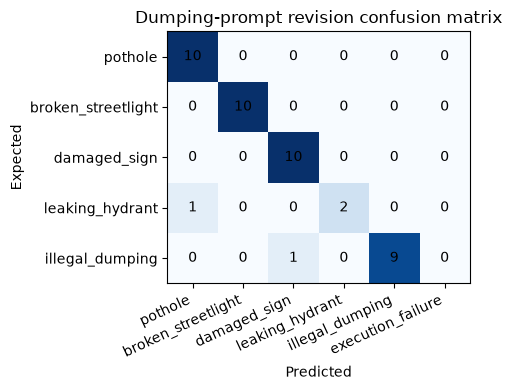

Latency seconds: {'mean': 0.03925270248856937, 'median': 0.0397017500072252, 'p95': 0.048465645808028056, 'maximum': 0.05190812499495223}
First image: 0.03298962500412017 | text prototype setup: 0.14734308299375698
Under 10 seconds: 43 / 43


,image_id,status,predicted_category,top1_margin,latency_seconds,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping
0,commons-04258228ae,success,damaged_sign,0.074337,0.032990,0.230991,0.203898,0.305328,0.148661,0.218580
1,commons-0a68e3b438,success,pothole,0.028746,0.038956,0.330434,0.301688,0.281791,0.265747,0.251225
2,commons-0f02ab33ca,success,illegal_dumping,0.040112,0.031699,0.207142,0.227462,0.246653,0.169867,0.286766
3,commons-1b000da556,success,leaking_hydrant,0.013369,0.030976,0.294854,0.266527,0.279302,0.308223,0.262641
4,commons-1be7ba9610,success,damaged_sign,0.043131,0.033634,0.260078,0.267627,0.310758,0.213668,0.267323
5,commons-1ce17d43d9,success,illegal_dumping,0.028936,0.031383,0.225072,0.242423,0.248749,0.209844,0.277686
6,commons-2409b4bbcb,success,broken_streetlight,0.064957,0.039634,0.168848,0.305442,0.240485,0.224369,0.190461
7,commons-289e64dab5,success,damaged_sign,0.051651,0.031185,0.224491,0.247198,0.318801,0.223411,0.267150
8,commons-359e62bbe5,success,illegal_dumping,0.035480,0.032042,0.262175,0.275373,0.282361,0.227579,0.317841
9,commons-3e69e554ed,success,pothole,0.076136,0.040916,0.363261,0.283015,0.287126,0.261293,0.225085


In [8]:
prompts_v2=load_prompts(HERE/'prompts/categories.v2.json')
changed=[k for k in CATEGORIES if prompts_v1['prompts'][k]!=prompts_v2['prompts'][k]]
assert changed==['illegal_dumping']
hypothesis={'changed_variable':'illegal_dumping text descriptions only',
            'baseline_configuration_sha256':baseline_cfg['configuration_sha256'],
            'expected_benefit':'Better recognition of a single abandoned appliance and scattered garden waste; may confuse structural debris.',
            'held_fixed':'checkpoint, four other prompt sets, three prompts/category, image IDs/order, transforms, scoring, metrics, CPU/float32/batch/threads/seed',
            'registered_before_revision_inference':True,
            'revision_prompts':prompts_v2}
write_new(RUN_ROOT/'targeted_change_before_run.json',hypothesis)
print(json.dumps(hypothesis,indent=2))
revision_cfg,revision_rows,revision_metrics=run(runtime,development,split,
    HERE/'prompts/categories.v2.json',RUN_ROOT/'revision')
assert_one_change(baseline_cfg,revision_cfg)
assert [r['image_id'] for r in baseline_rows]==[r['image_id'] for r in revision_rows]
print('Same-data, same-metric, one-variable comparison: PASS')
print('Revised frozen configuration:',revision_cfg['configuration_sha256'])
show_metrics(revision_metrics,'Dumping-prompt revision')
display(pd.DataFrame([{**{k:r.get(k) for k in ['image_id','status','predicted_category','top1_margin','latency_seconds']},
                      **r.get('scores',{})} for r in revision_rows]))

## Experiment comparison
Both runs below use the same 43 development photos. The comparison includes the score, number of examples, failures, latency and service cost, followed by the predictions that changed.

In [9]:
def experiment_row(name,cfg,metrics,change):
    return {'run':name,'model':'ViT-B-32 / openai / fp32 CPU','prompt_version':cfg['prompts']['version'],
            'change':change,'correct/N':f"{metrics['correct']}/{metrics['attempted_n']}",
            'accuracy':metrics['accuracy'],'macro_F1':metrics['macro_f1'],
            'N':metrics['attempted_n'],'failures':metrics['failures'],
            'latency_mean_s':metrics['latency_seconds']['mean'],'latency_p95_s':metrics['latency_seconds']['p95'],
            'service_USD':0}
comparison=pd.DataFrame([experiment_row('baseline',baseline_cfg,baseline_metrics,'none'),
                        experiment_row('revision',revision_cfg,revision_metrics,'dumping text only')])
display(comparison)
changes=[]
for left,right in zip(joined,revision_rows):
    if left.get('predicted_category')!=right.get('predicted_category'):
        changes.append({'image_id':left['image_id'],'expected':left['expected'],
                        'baseline':left.get('predicted_category'),'revision':right.get('predicted_category'),
                        'baseline_correct':left.get('predicted_category')==left['expected'],
                        'revision_correct':right.get('predicted_category')==left['expected']})
display(pd.DataFrame(changes))
delta=revision_metrics['accuracy']-baseline_metrics['accuracy']
f1_delta=revision_metrics['macro_f1']-baseline_metrics['macro_f1']
outcome='helped on these development cases' if delta>0 and f1_delta>0 else ('hurt on these development cases' if delta<0 and f1_delta<0 else 'mixed or no clear improvement')
print(f'Outcome: {outcome}; accuracy delta {delta:+.2%}; macro-F1 delta {f1_delta:+.4f}.')
print('Remaining revised errors:',[r['image_id'] for r in revision_rows
      if r['status']!='success' or r.get('predicted_category')!=truth[r['image_id']]])
print('External socket connection attempts during notebook:',len(network_attempts))
assert not network_attempts
# Save the comparison separately from the raw prediction files.
safe_summary={'dataset':{k:inspection[k] for k in ['dataset_version','dataset_commit','manifest_sha256','pool_n','development_n']},
              'baseline':{'configuration':baseline_cfg,'metrics':baseline_metrics},
              'revision':{'configuration':revision_cfg,'metrics':revision_metrics},
              'comparison':comparison.to_dict(orient='records'),'changed_predictions':changes,
              'outcome':outcome,'external_socket_attempts':len(network_attempts),
              'limitations':['development set reused after error analysis','agent-curated labels',
                             '3 hydrants, 2 caption-dependent','mostly daylight/nonlocal photos',
                             'unknown overlap with original CLIP pretraining',
                             'closed-set classifier has no irrelevant-image rejection',
                             'no final held-out or concurrency/load evaluation','CPU local timing excludes full app workflow']}
write_new(RUN_ROOT/'safe_summary.json',safe_summary)
print('Safe summary saved; publication export is a separate reviewed H6 step.')

,run,model,prompt_version,change,correct/N,accuracy,macro_F1,N,failures,latency_mean_s,latency_p95_s,service_USD
0,baseline,ViT-B-32 / openai / fp32 CPU,v1,none,40/43,0.930233,0.910072,43,0,0.039655,0.050806,0
1,revision,ViT-B-32 / openai / fp32 CPU,v2-dumping-visual-coverage,dumping text only,41/43,0.953488,0.930426,43,0,0.039253,0.048466,0


,image_id,expected,baseline,revision,baseline_correct,revision_correct
0,commons-7b78ffad33,illegal_dumping,pothole,illegal_dumping,False,True
1,commons-d374fa7f87,illegal_dumping,broken_streetlight,illegal_dumping,False,True
2,commons-dca2e40d63,illegal_dumping,illegal_dumping,damaged_sign,True,False


Outcome: helped on these development cases; accuracy delta +2.33%; macro-F1 delta +0.0204.
Remaining revised errors: ['commons-d5575814f4', 'commons-dca2e40d63']
External socket connection attempts during notebook: 0
Safe summary saved; publication export is a separate reviewed H6 step.


## Limitations and next steps
The sample is small, mostly daylight and outside Gainesville. Two of the three hydrant labels depend on captions, and overlap with CLIP's original pretraining data is unknown. The center crop can also remove useful detail.

CLIP always picks one of the five categories, even for unrelated images. Photos alone cannot establish dumping legality or an electrical fault.

The next evaluation needs separate photos, including unclear and unrelated cases. Qwen descriptions are evaluated in the next section; the reporting workflow remains future work. Rerun commands are in the [experiment README](README.md).

## Classification results

**The revised prompts got 41 of 43 photos correct (95.35%), compared with 40 of 43 (93.02%) for the baseline.**

| Run | Prompt change | Correct | Accuracy | Macro-F1 | Mean time per photo |
| --- | --- | ---: | ---: | ---: | ---: |
| Baseline | None | 40/43 | 93.02% | 0.9101 | 39.65 ms |
| Revised | Dumping descriptions only | 41/43 | 95.35% | 0.9304 | 39.25 ms |

**Results by category**

| Category | Baseline correct | Revised correct |
| --- | ---: | ---: |
| Pothole | 10/10 | 10/10 |
| Broken streetlight | 10/10 | 10/10 |
| Damaged sign | 10/10 | 10/10 |
| Leaking hydrant | 2/3 | 2/3 |
| Illegal dumping | 8/10 | 9/10 |

The change fixed the discarded-appliance and scattered-branches errors, but introduced one mistake on a rubble photo. That is a net gain of **one correct prediction**, or **2.33 percentage points**, with macro-F1 increasing from **0.9101 to 0.9304**. The wet-lane hydrant photo remained incorrect.

Both runs processed all 43 images with **zero execution failures** and **$0 in service charges**. Mean time was about 40 ms per photo on the Mac CPU, excluding model setup and the full app workflow. This does not establish the 100-request timing target.

The result supports keeping the revised prompts for the next evaluation, but a separate test set is needed before claiming better performance on new photos. Classification was explored first because pretrained CLIP provided a simple baseline on the available hardware. The next section evaluates descriptions. Destination routing remains outside these experiments.


## Description generation and evaluation

Qwen3-VL-4B-Instruct generated structured descriptions locally; the existing OpenCLIP checkpoint measured image–text alignment. Factual claims, missing details and latency were evaluated separately from similarity.

The original CLIP outputs above are preserved. **Qwen inference ran on October 22; these cells validate and display those saved real runs. They do not claim new inference.** Each section was executed in a separate kernel, so its execution counts restart. Running the whole notebook reruns classification and replays description evidence; the optional helper below can launch new Qwen runs.

In [1]:
import json, sys, subprocess, tempfile, html
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, HTML
from experiments.description_evaluation.contracts import read_jsonl, sha256, assert_one_change
from experiments.description_evaluation.report import load_run
from experiments.description_evaluation.run import validate_selection

DESC_ROOT = Path.cwd()
DESC = DESC_ROOT / "experiments/description_evaluation"
assert (DESC / "results.json").is_file(), "Run from the repository root"
selection = validate_selection()
evidence_manifest = json.loads((DESC / "evidence_manifest.json").read_text())
for name, expected in evidence_manifest["files"].items():
    assert sha256(DESC / name) == expected, name
assert sha256(DESC / "results.json") == evidence_manifest["results_sha256"]

# Recompute from original per-image records, not hand-entered table values.
with tempfile.TemporaryDirectory() as temporary:
    destination = Path(temporary) / "comparison.json"
    subprocess.run([sys.executable, "-m", "experiments.description_evaluation.report",
                    str(DESC / "evidence/baseline"), str(DESC / "evidence/revision"),
                    str(destination)], check=True, capture_output=True, text=True)
    desc_results = json.loads(destination.read_text())
assert desc_results == json.loads((DESC / "results.json").read_text())
desc_runs = {name: load_run(DESC / "evidence" / name) for name in ["baseline", "revision"]}
assert_one_change(desc_runs["baseline"][0], desc_runs["revision"][0])
print("Verified 40 real attempt records, 31 scores/reviews, frozen IDs/configurations and the exact saved comparison.")
print("Evidence replay only; no new model inference or visual review in this kernel.")

Verified 40 real attempt records, 31 scores/reviews, frozen IDs/configurations and the exact saved comparison.
Evidence replay only; no new model inference or visual review in this kernel.


### D0 — Data, model and review rules

The subset was frozen before generation: 4 potholes, 4 streetlights, 4 signs, all 3 hydrants and 5 dumping photos. All came from the existing development pool; final-test data was not used. Qwen received sanitized pixels and a fixed prompt, without captions, labels, filenames, coordinates or annotation notes.

The generator returns a tentative category, visible observations, a 1–2 sentence description, an outcome and clarification reasons. Invalid JSON/contracts remain failures. The fixed rubric counts unsupported assertions across **all fields**, clarity/specificity (0–2) and missing important visible facts. Zero unsupported claims among reviewed outputs is the factuality passing rule. Reviews are agent visual judgments, not independent human validation.

In [2]:
baseline_desc_cfg = desc_runs["baseline"][0]
settings = baseline_desc_cfg["settings"]
display(pd.DataFrame([
    {"setting": "Generator", "value": settings["model_id"]},
    {"setting": "Artifact", "value": settings["artifact_id"] + " @ " + settings["artifact_revision"]},
    {"setting": "Runtime", "value": "MLX-VLM 0.3.12; Apple M5 Metal; 24 GiB memory; local 4-bit"},
    {"setting": "Decoding", "value": f"temperature={settings['temperature']}; seed={settings['seed']}; max_tokens={settings['max_tokens']}"},
    {"setting": "Input", "value": f"RGB pixel copy; aspect-preserving max side {settings['generator_max_side']} px"},
    {"setting": "Scorer", "value": "Existing verified ViT-B-32/openai; native transforms/tokenizer; CPU fp32"},
    {"setting": "Score", "value": "dot(L2(image), L2(description)); no prefix/rescaling; raw cosine, not official CLIPScore"},
]).set_index("setting"))
display(pd.DataFrame(selection["images"])[["image_id", "issue_type", "author", "license"]])
print("Baseline prompt:\n" + baseline_desc_cfg["prompt"]["base"])
print("Schema required fields:", json.loads((DESC / "schemas.json").read_text())["generation"]["required"])
print("Exact model files, package versions, preprocessing and configurations remain in the submitted evidence files.")

,value
setting,
Generator,Qwen/Qwen3-VL-4B-Instruct
Artifact,mlx-community/Qwen3-VL-4B-Instruct-4bit @ 2fd8...
Runtime,MLX-VLM 0.3.12; Apple M5 Metal; 24 GiB memory;...
Decoding,temperature=0.0; seed=6216; max_tokens=384
Input,RGB pixel copy; aspect-preserving max side 768 px
Scorer,Existing verified ViT-B-32/openai; native tran...
Score,"dot(L2(image), L2(description)); no prefix/res..."


,image_id,issue_type,author,license
0,commons-0a68e3b438,pothole,Thomas Booker (CoderThomasB),CC BY-SA 4.0
1,commons-3e69e554ed,pothole,Snow storm in Eastern Asia at en.wikipedia,Public domain
2,commons-53a0d4c79e,pothole,Frankie Fouganthin,CC BY-SA 4.0
3,commons-8ecf201b0b,pothole,Uncl3dad,Public domain
4,commons-2409b4bbcb,broken_streetlight,ŠJů,CC BY 4.0
5,commons-4be599b76a,broken_streetlight,Laima Gūtmane (simka…,CC BY-SA 3.0
6,commons-81da3dfe1b,broken_streetlight,ŠJů,CC BY 4.0
7,commons-84bcb35daa,broken_streetlight,Jay Dobkin,CC BY-SA 4.0
8,commons-04258228ae,damaged_sign,Kenneth Allen,CC BY-SA 2.0
9,commons-1be7ba9610,damaged_sign,Kenneth Allen,CC BY-SA 2.0


Baseline prompt:
Describe the visible civic condition in this photograph for a draft issue report. Use only visible evidence. Do not invent locations, measurements, causes, legality, electrical faults or operating status. If uncertain, say what cannot be confirmed. There is no user observation. Return ONLY a JSON object with exactly these keys: category_suggestion (pothole, broken_streetlight, damaged_sign, leaking_hydrant, illegal_dumping, or null), visible_observations (array of short factual strings), description (1-2 short sentences, at most 60 words), outcome (supported, unclear, or unsupported), clarification_reasons (array of short strings). Category is a tentative suggestion, not confirmation that an issue exists. An unclear photograph can still have a description of what is visible. No markdown.
Schema required fields: ['image_id', 'run_id', 'category_suggestion', 'visible_observations', 'description', 'outcome', 'clarification_reasons', 'status', 'error_status', 'first_image_

### D1–D2 — Local generation and CLIP scoring

The optional helper launches the existing adapters in their isolated environments. It uses a new ignored run directory and never overwrites the original records. New generations require new visual reviews; the saved reviews are bound to the original outputs.

The scorer encodes the **original stored image** and generated description alone with the existing OpenCLIP model, L2-normalizes both embeddings and takes their dot product. It uses no category prototypes, score threshold or confidence percentage. Errors/empty-description abstentions have null scores; similarity does not validate factual claims.

In [3]:
def run_description_models(run_name, prompt_version="v1"):
    """Optional real local inference; not invoked during this evidence replay."""
    if prompt_version not in {"v1", "v2"} or Path(run_name).name != run_name:
        raise ValueError("Use a plain new run name and prompt v1/v2")
    target = DESC_ROOT / ".runtime/description-runs" / run_name
    if target.exists():
        raise FileExistsError("Choose a new run name; original evidence is immutable")
    qwen_python = DESC_ROOT / ".venv-inference/qwen/bin/python"
    if not qwen_python.is_file():
        raise RuntimeError("Install the pinned Qwen environment using the experiment README")
    subprocess.run([str(qwen_python), "-m", "experiments.description_evaluation.run", "generate",
                    str(target), "--prompt", str(DESC / "prompts" / f"{prompt_version}.json")], check=True)
    subprocess.run([sys.executable, "-m", "experiments.description_evaluation.run", "score", str(target)], check=True)
    print("Actual new outputs saved to", target, "— review these outputs before evaluating factuality.")
    return target

# To run new inference after installing/verifying local weights:
# baseline_new = run_description_models("baseline-new", "v1")
# Review baseline_new against rubric.json before choosing a prompt change.
print("Optional local generation/scoring helper defined; not invoked. Saved real runs are displayed below.")

Optional local generation/scoring helper defined; not invoked. Saved real runs are displayed below.


### D3 — Baseline outputs and factual review

All 20 attempts remain below, including failures. Every valid output was visually reviewed against the same photos and rubric. Expand the records for observations, atomic unsupported claims, review notes, provenance and failure diagnostics.

In [4]:
def show_description_run(name):
    cfg, generations, scores, reviews, scorer, metrics = desc_runs[name]
    score_by_id = {r["image_id"]: r for r in scores}
    review_by_id = {r["image_id"]: r for r in reviews}
    failures = {r["image_id"]: r for r in read_jsonl(DESC / "evidence" / name / "failure_diagnostics.jsonl")}
    table, records = [], []
    for row in generations:
        image_id = row["image_id"]
        score, review = score_by_id[image_id], review_by_id.get(image_id)
        failure = failures.get(image_id)
        table.append({"image_id": image_id, "status": row["status"],
                      "description": row["description"] or "Contract failure: " + failure["validation_message"],
                      "cosine": score["clip_cosine"],
                      "unsupported claims": review["unsupported_claim_count"] if review else None,
                      "missing fact": review["missing_important_visible_fact"] if review else None})
        records.append({"generation": row, "score": score, "review": review, "failure": failure})
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(pd.DataFrame(table).style.hide(axis="index").format({"cosine": "{:.4f}"}, na_rep="—")
                .set_properties(**{"white-space": "normal", "max-width": "360px", "vertical-align": "top"}))
    content = html.escape(json.dumps(records, indent=2))
    display(HTML("<details><summary>All per-image fields, reviews and diagnostics (" + name + ")</summary><pre>" + content + "</pre></details>"))
    print(f"{name}: {metrics['attempted']} attempts; {metrics['generated']} valid; {metrics['generation_failures']} failures; "
          f"{metrics['reviewed']} reviewed; {metrics['zero_unsupported_claims']} with zero unsupported claims.")

show_description_run("baseline")

image_id,status,description,cosine,unsupported claims,missing fact
commons-0a68e3b438,success,A damaged asphalt area with a circular depression contains debris. It is next to a square manhole cover with a diamond-patterned metal lid.,0.3425,0.000000,False
commons-3e69e554ed,success,"The road surface contains several potholes and a long white line, likely a painted marking. The pavement appears worn and damaged.",0.3725,0.000000,False
commons-53a0d4c79e,success,"A noticeable depression in the pavement with visible cracks and debris, including a leaf, inside the depression.",0.2912,0.000000,False
commons-8ecf201b0b,error,Contract failure: Description must contain at most two sentences,—,—,—
commons-2409b4bbcb,success,A streetlight fixture is visibly damaged and detached from its mount. Snow is present on the fixture and pole.,0.2892,0.000000,False
commons-4be599b76a,error,Contract failure: Unknown category,—,—,—
commons-81da3dfe1b,success,"The streetlight fixture shows signs of physical damage to its protective cover. Water droplets and a spiderweb are present, indicating exposure to the elements.",0.3443,1.000000,False
commons-84bcb35daa,success,A tall ornamental pole with a lantern at its base stands beside a pathway. Surrounding vegetation and distant traffic signs are visible.,0.3275,1.000000,True
commons-04258228ae,success,"A road sign is visibly damaged and tilted, resting on a fence. It is partially covered by grass and brush.",0.3032,1.000000,False
commons-1be7ba9610,success,"A stop sign shows signs of wear and damage, including chipped edges and a small attached sticker. The pole has graffiti.",0.3244,2.000000,True


baseline: 20 attempts; 16 valid; 4 failures; 16 reviewed; 8 with zero unsupported claims.


### D4 — One evidence-driven prompt change

Baseline review found guessed sign text, unsupported disposal status and denials of visible damage. A single final visual-evidence self-check was added. The base prompt, ordered photos, model/artifact, decoding, scorer, rubric and implementation stayed fixed. The hypothesis was recorded before the revised inference; no second improvement was attempted.

In [5]:
change = json.loads((DESC / "evidence/prompt_change_before_revision.json").read_text())
assert change["baseline_reviews_sha256"] == sha256(DESC / "evidence/baseline/reviews.jsonl")
assert change["registered_before_revision_inference"]
assert_one_change(desc_runs["baseline"][0], desc_runs["revision"][0])
print("One added feature:", change["exact_added_text"])
print("Expected benefit:", change["hypothesis"])
print("Possible regression:", change["possible_regressions"])
print("Same settings and same ordered 20 IDs: verified.")

One added feature: Before returning JSON, check every proposed assertion against the visible pixels and delete any assertion that is not directly observable.
Expected benefit: Deleting assertions that cannot be checked against the image should reduce guessed text, inferred disposal status and false absence/damage claims across all fields.
Possible regression: May omit useful details, reduce specificity, or alter formatting/category validity. No improvement assumed.
Same settings and same ordered 20 IDs: verified.


In [6]:
show_description_run("revision")

image_id,status,description,cosine,unsupported claims,missing fact
commons-0a68e3b438,success,A damaged asphalt area with a circular depression containing debris. Adjacent to it is a square metal manhole cover.,0.3366,0.000000,False
commons-3e69e554ed,error,Contract failure: Description must contain at most two sentences,—,—,—
commons-53a0d4c79e,success,"A noticeable depression in the pavement with visible cracks and debris, including a leaf, inside the depression.",0.2912,0.000000,False
commons-8ecf201b0b,success,"A significant pothole is visible on the road surface, filled with dark material. The road extends into the distance with trees on either side.",0.3511,0.000000,False
commons-2409b4bbcb,success,The streetlight fixture shows signs of physical damage at its attachment point. A green light is illuminated on the base.,0.3023,2.000000,False
commons-4be599b76a,error,Contract failure: Unknown category,—,—,—
commons-81da3dfe1b,success,"The streetlight fixture shows signs of physical damage to its protective cover and is wet, suggesting recent exposure to rain or condensation.",0.3391,1.000000,False
commons-84bcb35daa,error,Contract failure: Unknown category,—,—,—
commons-04258228ae,success,"A road sign is visibly tilted and partially obscured by vegetation, indicating physical damage and improper mounting.",0.3116,0.000000,False
commons-1be7ba9610,success,A stop sign shows signs of wear and a sticker is attached. Moss is present on the ground nearby.,0.3006,1.000000,True


revision: 20 attempts; 15 valid; 5 failures; 15 reviewed; 7 with zero unsupported claims.


### D5 — Results

The table separates coverage, alignment, factual review and latency. Scores use valid outputs only; timing includes all 20 attempts per run, including failures. Mean/p95 exclude loading and persistence, include the cold first image and measure sequential local generation rather than application latency.

In [7]:
rows = []
for name in ["baseline", "revision"]:
    m = desc_results[name]
    rows.append({"run": name, "model / prompt": "Qwen3-VL-4B MLX 4-bit / " + desc_runs[name][0]["prompt_version"],
        "attempted / valid / reviewed": f"{m['attempted']} / {m['generated']} / {m['reviewed']}",
        "mean raw cosine": m["mean_clip_cosine"],
        "zero unsupported / reviewed": f"{m['zero_unsupported_claims']} / {m['reviewed']}",
        "clarity / specificity": f"{m['mean_clarity']:.2f} / {m['mean_specificity']:.2f}",
        "mean / p95 seconds": f"{m['generation_latency_seconds']['mean']:.3f} / {m['generation_latency_seconds']['p95']:.3f}"})
display(pd.DataFrame(rows).set_index("run").round(6))
pairs = desc_results["paired_metrics"]
print(f"Shared reviewed/scored cases: {pairs['reviewed_pair_n']}; zero-unsupported {pairs['baseline_zero_unsupported_on_pairs']}/14 → {pairs['revision_zero_unsupported_on_pairs']}/14.")
print(f"Factuality fixes: {desc_results['factuality_fixes']}; regressions: {desc_results['factuality_regressions']}; paired mean cosine change: {pairs['mean_cosine_delta']:+.6f}.")
print(f"Missing important facts: baseline {desc_results['baseline']['missing_important_visible_fact_n']}/16, revision {desc_results['revision']['missing_important_visible_fact_n']}/15; paired change {pairs['missing_fact_delta']}.")
print("The prompt change did not improve results. Higher cosine alone did not imply factual correctness.")

,model / prompt,attempted / valid / reviewed,mean raw cosine,zero unsupported / reviewed,clarity / specificity,mean / p95 seconds
run,,,,,,
baseline,Qwen3-VL-4B MLX 4-bit / description-v1,20 / 16 / 16,0.327345,8 / 16,1.94 / 1.75,8.148 / 10.283
revision,Qwen3-VL-4B MLX 4-bit / description-v2,20 / 15 / 15,0.324122,7 / 15,2.00 / 1.80,7.868 / 10.022


Shared reviewed/scored cases: 14; zero-unsupported 7/14 → 6/14.
Factuality fixes: 1; regressions: 2; paired mean cosine change: -0.001909.
Missing important facts: baseline 4/16, revision 3/15; paired change 0.
The prompt change did not improve results. Higher cosine alone did not imply factual correctness.


### Fixes and regressions in the same photos

The leaning-sign attachment claim was removed. The globe-light revision invented a green indicator and operating status; its cosine nevertheless increased. The fence-side waste revision inferred serviceability and site designation. Both water-plume descriptions avoided identifying an unseen hydrant body or a leak cause.

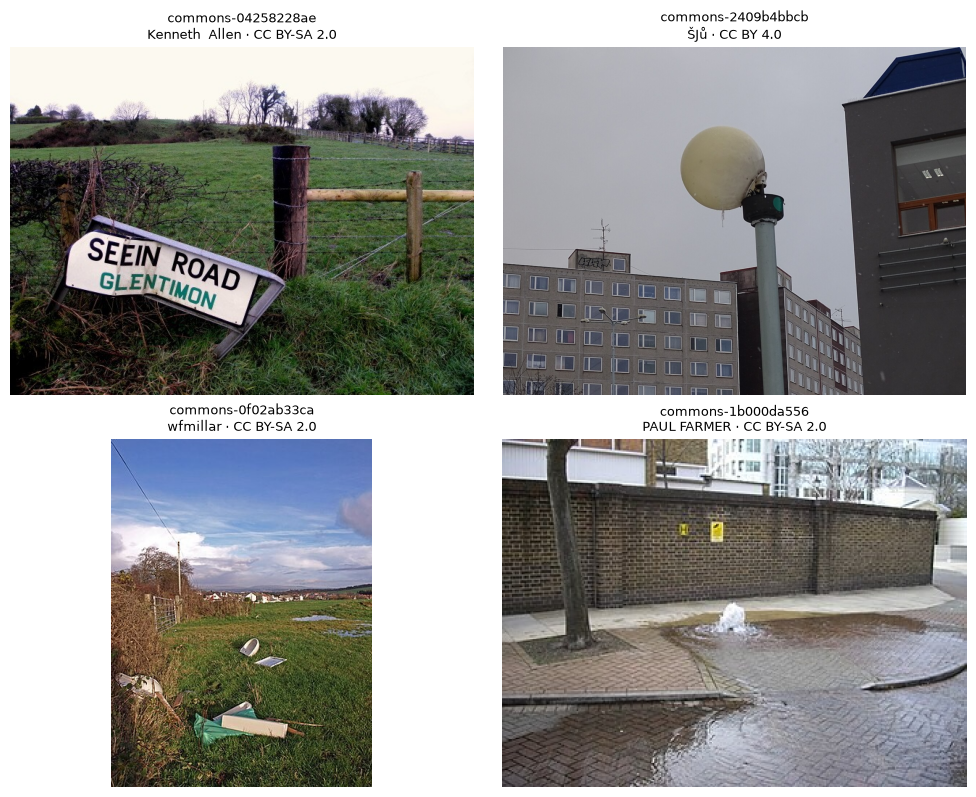

image_id,run,description,unsupported claims,claim notes (all fields),paired cosine change
commons-04258228ae,baseline,"A road sign is visibly damaged and tilted, resting on a fence. It is partially covered by grass and brush.",1,The observation says the sign is mounted to a fence post; an actual attachment is not visible.,+0.008424
commons-04258228ae,revision,"A road sign is visibly tilted and partially obscured by vegetation, indicating physical damage and improper mounting.",0,No unsupported claim found,+0.008424
commons-2409b4bbcb,baseline,A streetlight fixture is visibly damaged and detached from its mount. Snow is present on the fixture and pole.,0,No unsupported claim found,+0.013173
commons-2409b4bbcb,revision,The streetlight fixture shows signs of physical damage at its attachment point. A green light is illuminated on the base.,2,"The turquoise patch on the fixture base is asserted to be an illuminated green light, which the photo does not establish.; The supposed green light is used to infer an operational state, which cannot be established from the image.",+0.013173
commons-0f02ab33ca,baseline,Discarded objects are visible on grass near a fence. No signs of active use or maintenance are present.,0,No unsupported claim found,-0.001092
commons-0f02ab33ca,revision,Discarded objects are visible on grass near a fence. No signs of active use or damage to infrastructure are present.,2,"The clarification asserts the objects are not serviceable, which a still photo does not establish.; The clarification rules out a utility-area designation, which is not visually established.",-0.001092
commons-1b000da556,baseline,"Water is actively jetting from the ground near a tree, creating a pool and flow on the pavement. A yellow sign is affixed to a brick wall nearby.",0,No unsupported claim found,-0.036900
commons-1b000da556,revision,Water is actively jetting from the ground and pooling nearby. A yellow sign is affixed to a brick wall in the background.,0,No unsupported claim found,-0.036900


In [8]:
case_ids = ["commons-04258228ae", "commons-2409b4bbcb", "commons-0f02ab33ca", "commons-1b000da556"]
photos = {r["image_id"]: r for r in selection["images"]}
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, image_id in zip(axes.flat, case_ids):
    photo = photos[image_id]
    with Image.open(DESC_ROOT / "data" / photo["filename"]) as photo_image:
        ax.imshow(photo_image)
    ax.set_title(image_id + "\n" + photo["author"] + " · " + photo["license"], fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()
case_rows = []
for image_id in case_ids:
    pair = next(r for r in desc_results["paired"] if r["image_id"] == image_id)
    for name in ["baseline", "revision"]:
        generation = next(r for r in desc_runs[name][1] if r["image_id"] == image_id)
        review = next(r for r in desc_runs[name][3] if r["image_id"] == image_id)
        case_rows.append({"image_id": image_id, "run": name, "description": generation["description"],
                          "unsupported claims": review["unsupported_claim_count"],
                          "claim notes (all fields)": "; ".join(review["unsupported_claims"]) or "No unsupported claim found",
                          "paired cosine change": pair["clip_cosine_delta"]})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(case_rows).style.hide(axis="index").format({"paired cosine change": "{:+.6f}"})
            .set_properties(**{"white-space": "normal", "max-width": "320px", "vertical-align": "top"}))

In [9]:
failure_rows = []
for name in ["baseline", "revision"]:
    for row in read_jsonl(DESC / "evidence" / name / "failure_diagnostics.jsonl"):
        failure_rows.append({"run": name, "image_id": row["image_id"], "first contract error": row["validation_message"]})
display(pd.DataFrame(failure_rows))
print("First errors: string 'null' instead of JSON null, or too many description sentences. No repair/retry; no factuality passes for failures.")
print("Empty-description abstentions: 0 in both runs. A nonempty model 'unsupported' outcome was still reviewed, not trusted as a verdict.")
print("Validation: 22 harness/classifier/dataset tests passed in the saved experiment; evidence recomputation passed in this notebook.")
print("D0–D5 description evaluation complete. No held-out, independent-human or application acceptance claim.")

,run,image_id,first contract error
0,baseline,commons-8ecf201b0b,Description must contain at most two sentences
1,baseline,commons-4be599b76a,Unknown category
2,baseline,commons-d5575814f4,Unknown category
3,baseline,commons-7b78ffad33,Description must contain at most two sentences
4,revision,commons-3e69e554ed,Description must contain at most two sentences
5,revision,commons-4be599b76a,Unknown category
6,revision,commons-84bcb35daa,Unknown category
7,revision,commons-d5575814f4,Unknown category
8,revision,commons-7b78ffad33,Description must contain at most two sentences


First errors: string 'null' instead of JSON null, or too many description sentences. No repair/retry; no factuality passes for failures.
Empty-description abstentions: 0 in both runs. A nonempty model 'unsupported' outcome was still reviewed, not trusted as a verdict.
Validation: 22 harness/classifier/dataset tests passed in the saved experiment; evidence recomputation passed in this notebook.
D0–D5 description evaluation complete. No held-out, independent-human or application acceptance claim.


## Combined conclusion

CLIP's dumping-prompt change improved classification from **40/43 to 41/43** on reused development photos. The Qwen self-check prompt did **not** improve descriptions: valid outputs fell **16 → 15**, with zero unsupported claims in **8/16 → 7/15** reviewed outputs. On 14 shared cases there was one fix and two regressions.

Keep factual review separate from image–text similarity. These small, previously inspected datasets and agent reviews do not establish unseen-photo reliability. Further work needs independent review and new held-out photos; no app integration or automatic report approval was added.

Submit this notebook with its repository support files. [Reproduction instructions](../description_evaluation/README.md) · [per-image evidence](../description_evaluation/evidence/) · [short findings](../description_evaluation/FINDINGS.md).